# 09 · MODFLOW 6 flow bridge (experimental)

Export a SubsurfiX property grid to a [MODFLOW 6](https://doi.org/10.3133/tm6A55) groundwater-flow (GWF) model with
[FloPy](https://doi.org/10.1111/gwat.13259), run it, and compare with the SubsurfiX finite-volume pressure solver.

Conversions in `subsurfix.modflow` (SI units): hydraulic conductivity K = k·ρg/μ, specific storage
Ss = ρg(c_rock + φ·c_w), well connection conductance C = WI·ρg/μ with Peaceman well indices
([Peaceman 1978](https://doi.org/10.2118/6893-PA)), and pressure p = ρg·h. MODFLOW 6 is single-phase and
constant-density, so this compares the single-phase, steady pressure field, not the two-phase run of notebook 05.

Fluid here: injected water, ρ = 1050 kg/m³, μ = 5×10⁻⁴ Pa·s (notebook 05 values).
Needs the `mf6` binary: `get-modflow :flopy` (installed with FloPy).

## Setup
A small self-contained layered block model (`block_model.py` next to this notebook): no external data needed.

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

%matplotlib inline
from subsurfix import _native as nat
from subsurfix import modflow

OUT = Path(os.environ.get("SX_EXAMPLE_OUT", "outputs")).resolve()
OUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 80, "savefig.dpi": 110})
def save(fig, name):
    fig.savefig(OUT / name, bbox_inches="tight")
print("mf6 found:", modflow.mf6_available())

mf6 found: True


## Block model
10 × 10 × 12 cells of 500 × 500 × 5 m in four units of three layers, each with one porosity and permeability
(kv/kh = 0.1):

In [2]:
from IPython.display import Markdown, display
from block_model import column_wells, layered_block, describe
bm = layered_block()
origin, cell, dims, phi, perm, k_md = bm["origin"], bm["cell"], bm["dims"], bm["phi"], bm["perm"], bm["k_md"]
nx, ny, nz = dims
n = nx * ny * nz
display(Markdown(describe(bm)))
print(n, "cells | median k", np.median(k_md).round(2), "mD")

| Unit | Layers | Porosity | k (mD) |
|---|---|---|---|
| upper sand | 0–2 | 0.12 | 5 |
| main sand | 3–5 | 0.22 | 80 |
| shaly baffle | 6–8 | 0.06 | 0.5 |
| lower sand | 9–11 | 0.16 | 20 |

1200 cells | median k 12.5 mD


## Wells
Vertical injector at (5, 5) injecting 0.02 m³/s, vertical producer at (2, 2) held at 15 MPa, both open in all layers.

In [3]:
rho, mu = 1050.0, 5e-4
wells = column_wells(bm, rate=0.02, bhp=1.5e7)

## SubsurfiX pressure solve (steady, single-phase)

In [4]:
m = nat.FlowModel.from_regular(origin, cell, dims, perm, phi)
sol = m.solve_pressure(np.full(n, 1 / mu), wells)
p_ssx = np.asarray(sol["p"])
print({w["name"]: round(w["rate"], 5) for w in sol["wells"]}, "m3/s; INJ bhp", round(sol["wells"][0]["bhp"] / 1e6, 3), "MPa")

{'INJ': 0.02, 'PROD': -0.02} m3/s; INJ bhp 36.111 MPa


## Same model in MODFLOW 6

In [5]:
sim = modflow.to_modflow6(OUT / "mf6_09", origin, cell, dims, perm, phi, wells, rho=rho, mu=mu)
modflow.run_modflow6(sim)
res = modflow.read_modflow6(sim)
p_mf = res["p"][0]
print({w["name"]: round(w["rate"], 5) for w in res["wells"]}, "m3/s; INJ bhp", round(res["wells"][0]["bhp"] / 1e6, 3), "MPa")

{'inj': 0.02, 'prod': -0.02} m3/s; INJ bhp 36.111 MPa


## Comparison

max |Δp| difference 4.752e-02 Pa = 3.37e-09 of the max overpressure
injector bhp: SubsurfiX 36.1114 MPa, MODFLOW 6 36.1114 MPa


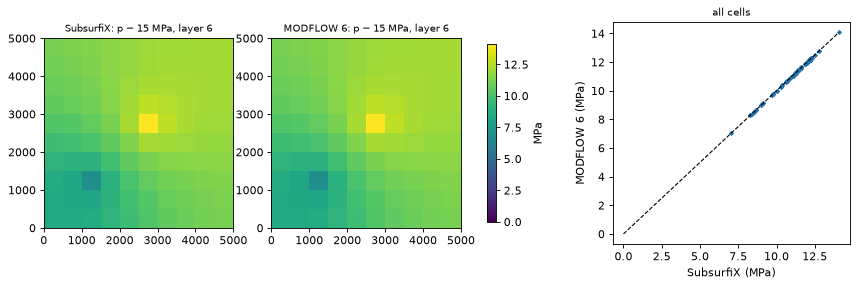

In [6]:
dp_ssx, dp_mf = p_ssx - 1.5e7, p_mf - 1.5e7
err = np.abs(dp_mf - dp_ssx)
print(f"max |Δp| difference {err.max():.3e} Pa = {err.max() / np.abs(dp_ssx).max():.2e} of the max overpressure")
print(f"injector bhp: SubsurfiX {sol['wells'][0]['bhp'] / 1e6:.4f} MPa, MODFLOW 6 {res['wells'][0]['bhp'] / 1e6:.4f} MPa")
fig, axs = plt.subplots(1, 3, figsize=(13, 3.6))
ext = [origin[0], origin[0] + nx * cell[0], origin[1], origin[1] + ny * cell[1]]
lay = nz // 2
vmax = max(dp_ssx.max(), dp_mf.max()) / 1e6
for ax, a, t in zip(axs[:2], (dp_ssx, dp_mf), ("SubsurfiX", "MODFLOW 6")):
    im = ax.imshow(a.reshape(nz, ny, nx)[lay] / 1e6, origin="lower", extent=ext, vmin=0, vmax=vmax, cmap="viridis")
    ax.set_title(f"{t}: p − 15 MPa, layer {lay}", fontsize=9)
fig.colorbar(im, ax=axs[:2], shrink=0.8, label="MPa")
axs[2].plot(dp_ssx / 1e6, dp_mf / 1e6, ".", ms=4); axs[2].plot([0, vmax], [0, vmax], "k--", lw=1)
axs[2].set_xlabel("SubsurfiX (MPa)"); axs[2].set_ylabel("MODFLOW 6 (MPa)"); axs[2].set_title("all cells", fontsize=9)
save(fig, "09_mf6_vs_subsurfix.png")

## Transient run in MODFLOW 6
Storage from notebook 05's compressibilities (c_rock = 5×10⁻¹⁰, c_w = 4×10⁻¹⁰ 1/Pa), starting at 15 MPa.
Injector bottom-hole pressure over time, approaching the steady value above.

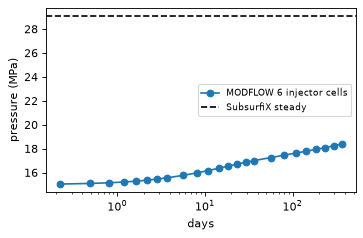

In [7]:
yr = 3.156e7
sim_t = modflow.to_modflow6(OUT / "mf6_09t", origin, cell, dims, perm, phi, wells, rho=rho, mu=mu,
                            c_rock=5e-10, c_w=4e-10, p0=1.5e7, times=[0.01 * yr, 0.1 * yr, 1 * yr], nstp=8)
modflow.run_modflow6(sim_t)
rt = modflow.read_modflow6(sim_t)
inj = wells[0]["cells"]
fig, ax = plt.subplots(figsize=(5, 3))
ax.semilogx(rt["times"] / 86400, rt["p"][:, inj].mean(axis=1) / 1e6, "o-", label="MODFLOW 6 injector cells")
ax.axhline(p_ssx[inj].mean() / 1e6, color="k", ls="--", label="SubsurfiX steady")
ax.set_xlabel("days"); ax.set_ylabel("pressure (MPa)"); ax.legend(fontsize=8); save(fig, "09_mf6_transient.png")

## Agreement and differences
* Both codes use two-point flux with harmonic-mean face conductances on a regular grid, so the steady pressure fields
  should agree to solver tolerance; the printed difference above is the check.
* MODFLOW 6 solves for hydraulic head with constant density. The bridge maps p = ρg·h, which matches
  SubsurfiX's gravity-free `solve_pressure`. Two-phase flow, capillary pressure and gravity segregation
  (notebook 05) have no MODFLOW 6 counterpart.
* Wells: the MAW package with specified conductance (Peaceman WI·ρg/μ) reproduces the SubsurfiX well model.
  MAW's own conductance equations (THIEM, SKIN) would differ slightly.
* The bridge supports regular grids only; corner-point grids (notebook 03) would need DISV/DISU.